In [1]:
import tensorflow as tf 
print(tf.version) 

<module 'tensorflow._api.v2.version' from 'C:\\Users\\tejas\\AppData\\Local\\Programs\\Python\\Python311\\Lib\\site-packages\\tensorflow\\_api\\v2\\version\\__init__.py'>


In [2]:
string = tf.Variable("this is a string", tf.string) 
number = tf.Variable(324, tf.int16)
floating = tf.Variable(3.567, tf.float64)

In [3]:
rank1_tensor = tf.Variable(["Test"], tf.string) 
rank2_tensor = tf.Variable([["test", "ok"], ["test", "yes"]], tf.string)

In [4]:
tf.rank(rank2_tensor)

<tf.Tensor: shape=(), dtype=int32, numpy=2>

In [5]:
rank2_tensor.shape

TensorShape([2, 2])

In [6]:
tensor1 = tf.ones([1,2,3])  
tensor2 = tf.reshape(tensor1, [2,3,1]) 
tensor3 = tf.reshape(tensor2, [3, -1])
print(tensor1)
print(tensor2)
print(tensor3)

tf.Tensor(
[[[1. 1. 1.]
  [1. 1. 1.]]], shape=(1, 2, 3), dtype=float32)
tf.Tensor(
[[[1.]
  [1.]
  [1.]]

 [[1.]
  [1.]
  [1.]]], shape=(2, 3, 1), dtype=float32)
tf.Tensor(
[[1. 1.]
 [1. 1.]
 [1. 1.]], shape=(3, 2), dtype=float32)


In [7]:
matrix = [[1,2,3,4,5],
          [6,7,8,9,10],
          [11,12,13,14,15],
          [16,17,18,19,20]]

tensor = tf.Variable(matrix, dtype=tf.int32) 
print(tf.rank(tensor))
print(tensor.shape)

tf.Tensor(2, shape=(), dtype=int32)
(4, 5)


In [8]:
three = tensor[0,2] 
print(three)  
row1 = tensor[0]  
print(row1)
column1 = tensor[:, 0]  
print(column1)
row_2_and_4 = tensor[1::2] 
print(row_2_and_4)
column_1_in_row_2_and_3 = tensor[1:3, 0]
print(column_1_in_row_2_and_3)

tf.Tensor(3, shape=(), dtype=int32)
tf.Tensor([1 2 3 4 5], shape=(5,), dtype=int32)
tf.Tensor([ 1  6 11 16], shape=(4,), dtype=int32)
tf.Tensor(
[[ 6  7  8  9 10]
 [16 17 18 19 20]], shape=(2, 5), dtype=int32)
tf.Tensor([ 6 11], shape=(2,), dtype=int32)


In [9]:
variable = tf.Variable([1, 2, 3])
constant = tf.constant([4, 5, 6])
print("Variable:", variable.numpy())
print("Constant:", constant.numpy())
variable.assign([7, 8, 9])
print("Updated Variable:", variable.numpy())

Variable: [1 2 3]
Constant: [4 5 6]
Updated Variable: [7 8 9]


In [10]:
a = tf.constant([10, 20, 30])
b = tf.constant([1, 2, 3])
print("Addition:", tf.add(a, b).numpy())
print("Subtraction:", tf.subtract(a, b).numpy())
print("Multiplication:", tf.multiply(a, b).numpy())
print("Division:", tf.divide(a, b).numpy())

Addition: [11 22 33]
Subtraction: [ 9 18 27]
Multiplication: [10 40 90]
Division: [10. 10. 10.]


In [11]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

(np.float64(0.0), np.float64(6.0), np.float64(0.0), np.float64(20.0))

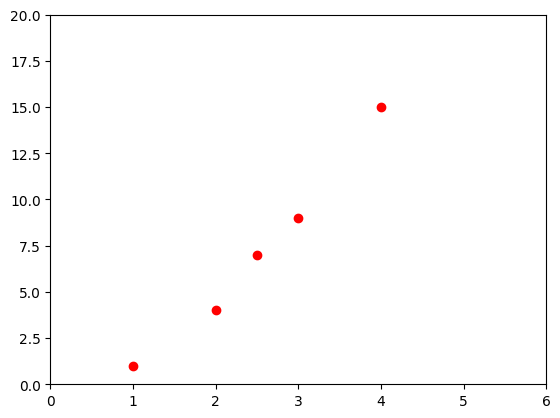

In [12]:
import matplotlib.pyplot as plt
import numpy as np
x = [1, 2, 2.5, 3, 4]
y = [1, 4, 7, 9, 15]
plt.plot(x, y, 'ro')
plt.axis([0, 6, 0, 20])

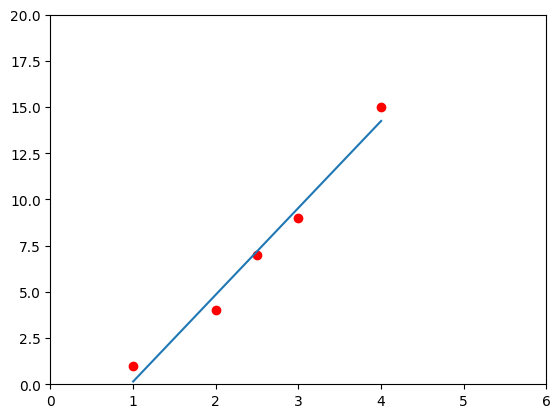

In [13]:
plt.plot(x, y, 'ro')
plt.axis([0, 6, 0, 20])
plt.plot(np.unique(x), np.poly1d(np.polyfit(x, y, 1))(np.unique(x)))
plt.show()

In [24]:
df=pd.read_csv('Iris.csv')
print(df.head())
print(df.shape)
print(df.columns.tolist())

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa
(150, 6)
['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']


In [25]:
df = df.drop(columns=["Id"])
X = df.drop(columns=["Species"])
y = df["Species"]
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Species:", y.unique())

Features shape: (150, 4)
Target shape: (150,)
Species: ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']


In [26]:
encoder = LabelEncoder()
y = encoder.fit_transform(y)
print("Species mapping:")
for i, species in enumerate(encoder.classes_):
    print(i, "=", species)

Species mapping:
0 = Iris-setosa
1 = Iris-versicolor
2 = Iris-virginica


In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (120, 4)
X_test: (30, 4)
y_train: (120,)
y_test: (30,)


In [28]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype("float32")
X_test = scaler.transform(X_test).astype("float32")
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (120, 4)
Testing data: (30, 4)


In [29]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4,)),
    tf.keras.layers.Dense(30, activation="relu"),
    tf.keras.layers.Dense(10, activation="relu"),
    tf.keras.layers.Dense(3, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                      │ (None, 30)                  │             150 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 10)                  │             310 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 3)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 493 (1.93 KB)

 Trainable params: 493 (1.93 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

Epoch 1/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 121ms/step - accuracy: 0.1875 - loss: 1.0939 - val_accuracy: 0.4167 - val_loss: 1.0807
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.4062 - loss: 1.0312 - val_accuracy: 0.5833 - val_loss: 1.0227
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.6042 - loss: 0.9749 - val_accuracy: 0.7083 - val_loss: 0.9707
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.6875 - loss: 0.9279 - val_accuracy: 0.7083 - val_loss: 0.9250
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.7083 - loss: 0.8828 - val_accuracy: 0.7083 - val_loss: 0.8888
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.7604 - loss: 0.8465 - val_accuracy: 0.7083 - val_loss: 0.8577
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.7812 - loss: 0.8119 - val_accuracy: 0.7083 - val_loss: 0.8299
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.8021 - loss: 0.7823 - val_accuracy: 0.7083 - val_loss

In [31]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

print("Test Loss:", loss)
print("Test Accuracy:", round(accuracy * 100, 2), "%")

Test Loss: 0.13900089263916016
Test Accuracy: 93.33 %


In [32]:
y_prob = model.predict(X_test)
y_pred = np.argmax(y_prob, axis=1)
print("Actual labels:   ", y_test[:10])
print("Predicted labels:", y_pred[:10])
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=encoder.classes_
))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step
Actual labels:    [0 2 1 1 0 1 0 0 2 1]
Predicted labels: [0 2 1 1 0 1 0 0 2 1]

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


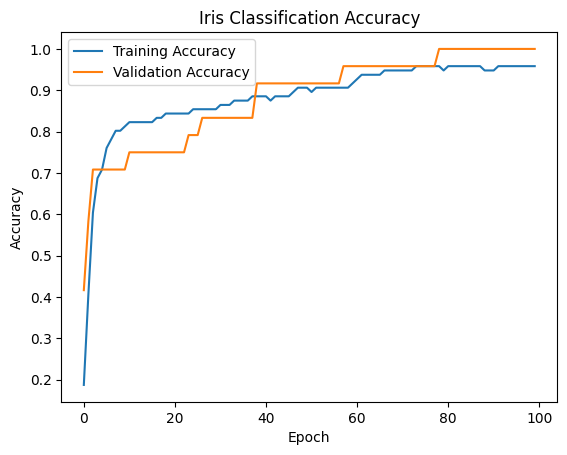

In [33]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Iris Classification Accuracy")
plt.legend()
plt.show()

In [34]:
new_flower = np.array([[5.1, 3.5, 1.4, 0.2]])
new_flower_scaled = scaler.transform(new_flower).astype("float32")
prediction = model.predict(new_flower_scaled, verbose=0)
predicted_index = np.argmax(prediction[0])
print("Predicted Species:", encoder.classes_[predicted_index])
print("Confidence:", round(float(np.max(prediction[0])) * 100, 2), "%")

C:\Users\tejas\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Predicted Species: Iris-setosa
Confidence: 99.84 %
